In [1]:
import numpy as np
import pandas as pd
from google.colab import drive

# 1. Mount Google Drive (this links your Colab to your Drive where your train.csv is stored)
print("Mounting Google Drive...")
drive.mount("/content/drive")

Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# 2. Define your file path
# (Update this path if your train.csv is inside a specific folder in your Google Drive)
file_path = "/content/drive/MyDrive/ML projects/train.csv"

In [3]:
# 3. Load a sample of the training dataset (e.g., 20,000 rows)
# WHY: Prevents Out-Of-Memory (OOM) crashes while prototyping on gigabyte-scale data.
print("Loading training dataset...")
df = pd.read_csv(file_path, nrows=20000)
print("Training data loaded successfully!\n")

Loading training dataset...
Training data loaded successfully!



In [4]:
# 4. Structural Profiling: Inspect shape and columns
print("--- DATASET SHAPE ---")
print(f"Total Rows: {df.shape[0]}, Total Features: {df.shape[1]}")

print("\n--- FIRST 5 ROWS ---")
display(df.head())

print("\n--- DATA TYPES & MEMORY INFO ---")
df.info()

--- DATASET SHAPE ---
Total Rows: 20000, Total Features: 47

--- FIRST 5 ROWS ---


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,757.00,6.00,64.00,23.671858,23.671858,0.0,0.0,0.0,0.0,...,538.470740,944.00,8.334058e+07,9.5,41.845546,761.456760,305219.322301,0.95,141.55,DDoS-ACK_Fragmentation
1,0.000000,54.00,6.00,64.00,2.393046,2.393046,0.0,0.0,1.0,0.0,...,0.000000,54.00,8.309327e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DDoS-SYN_Flood
2,0.033982,56.78,6.11,64.64,1.192715,1.192715,0.0,0.0,0.0,0.0,...,1.727526,54.29,8.333086e+07,9.5,10.462813,2.445286,16.853118,0.19,141.55,DDoS-PSHACK_Flood
3,0.000000,0.00,47.00,64.00,9.841972,9.841972,0.0,0.0,0.0,0.0,...,0.000000,592.00,8.370278e+07,9.5,34.409301,0.000000,0.000000,0.00,141.55,Mirai-greeth_flood
4,3.944828,108.00,6.00,64.00,0.506993,0.506993,0.0,0.0,1.0,0.0,...,0.000000,54.00,8.297270e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DoS-SYN_Flood



--- DATA TYPES & MEMORY INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 47 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   flow_duration    20000 non-null  float64
 1   Header_Length    20000 non-null  float64
 2   Protocol Type    20000 non-null  float64
 3   Duration         20000 non-null  float64
 4   Rate             20000 non-null  float64
 5   Srate            20000 non-null  float64
 6   Drate            20000 non-null  float64
 7   fin_flag_number  20000 non-null  float64
 8   syn_flag_number  20000 non-null  float64
 9   rst_flag_number  20000 non-null  float64
 10  psh_flag_number  20000 non-null  float64
 11  ack_flag_number  20000 non-null  float64
 12  ece_flag_number  20000 non-null  float64
 13  cwr_flag_number  20000 non-null  float64
 14  ack_count        20000 non-null  float64
 15  syn_count        20000 non-null  float64
 16  fin_count        20000 n

Checking for infinite or missing values...
Null values found per column:
 0


/tmp/ipykernel_19790/766053774.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


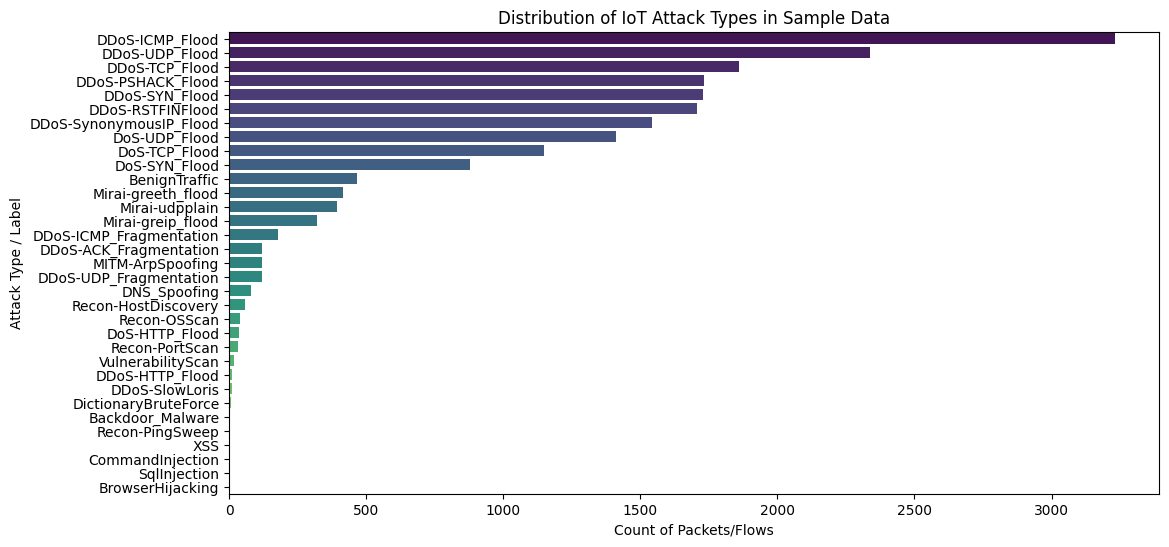

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Check for missing   or infinite values (Network data often has division-by-zero infinities)
print("Checking for infinite or missing values...")
df.replace([np.inf, -np.inf], np.nan, inplace=True)
print("Null values found per column:\n", df.isnull().sum().sum())

# Clean them by dropping rows with NaN
df.dropna(inplace=True)

# 2. Plot the distribution of attacks (Class Distribution)
# This shows your teacher that you know which attacks are most common in your sample.
plt.figure(figsize=(12, 6))
sns.countplot(
    y="label",
    data=df,
    order=df["label"].value_counts().index,
    palette="viridis",
)
plt.title("Distribution of IoT Attack Types in Sample Data")
plt.xlabel("Count of Packets/Flows")
plt.ylabel("Attack Type / Label")
plt.show()

In [6]:
# 1. Summary Statistics (Shows min, max, mean, and spread of every network feature)
print("--- SUMMARY STATISTICS ---")
display(df.describe())

# 2. Check for duplicate rows (Very common in network traffic logs)
print("\n--- DUPLICATE ROWS ---")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

--- SUMMARY STATISTICS ---


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight
count,20000.000000,2.000000e+04,20000.000000,20000.000000,2.000000e+04,2.000000e+04,2.000000e+04,20000.00000,20000.000000,20000.000000,...,20000.000000,20000.000000,20000.000000,2.000000e+04,20000.000000,20000.000000,20000.000000,2.000000e+04,20000.000000,20000.000000
mean,6.010302,7.369115e+04,9.014825,66.287588,9.591088e+03,9.591088e+03,3.849401e-07,0.08525,0.207150,0.089500,...,123.007958,32.317445,123.790772,8.312772e+07,9.495770,13.055598,45.674691,2.816558e+04,0.094303,141.444982
std,342.123574,4.408028e+05,8.920930,13.833571,1.020854e+05,1.020854e+05,5.443875e-05,0.27926,0.405274,0.285471,...,236.309652,152.682876,240.435243,1.681838e+07,0.809128,8.535569,215.921144,2.250893e+05,0.229882,20.797770
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.00000,0.000000,0.000000,...,42.000000,0.000000,42.000000,5.364418e-07,2.000000,9.165151,0.000000,0.000000e+00,0.000000,4.666667
25%,0.000000,5.400000e+01,6.000000,64.000000,2.063914e+00,2.063914e+00,0.000000e+00,0.00000,0.000000,0.000000,...,50.000000,0.000000,50.000000,8.307200e+07,9.500000,10.000000,0.000000,0.000000e+00,0.000000,141.550000
50%,0.000000,5.400000e+01,6.000000,64.000000,1.539792e+01,1.539792e+01,0.000000e+00,0.00000,0.000000,0.000000,...,54.000000,0.000000,54.000000,8.312463e+07,9.500000,10.392305,0.000000,0.000000e+00,0.000000,141.550000
75%,0.103610,3.034425e+02,14.532500,64.000000,1.166332e+02,1.166332e+02,0.000000e+00,0.00000,0.000000,0.000000,...,54.037965,0.357419,54.060000,8.334388e+07,9.500000,10.395385,0.485827,1.258771e+00,0.080000,141.550000
max,47676.406563,9.335366e+06,47.000000,255.000000,3.145728e+06,3.145728e+06,7.698801e-03,1.00000,1.000000,1.000000,...,4017.674008,3081.526463,3380.300000,1.676392e+08,13.500000,88.561406,4366.242121,9.561869e+06,1.000000,244.600000



--- DUPLICATE ROWS ---
Number of duplicate rows: 3


In [7]:
#DATA CLEANING

# 1. Drop columns that have zero variance (like ece and cwr flags if they are all 0)
constant_cols = [
    col for col in df.columns if df[col].nunique() == 1 and col != "label"
]
print(f"Dropping constant/useless columns with zero variance: {constant_cols}")
df.drop(columns=constant_cols, inplace=True)

print(df.shape)

Dropping constant/useless columns with zero variance: ['ece_flag_number', 'cwr_flag_number', 'Telnet', 'SMTP', 'SSH', 'IRC', 'DHCP']
(20000, 40)


In [8]:
# 2. Replace infinite values with NaN and drop them
df.replace([np.inf, -np.inf], np.nan, inplace=True)
initial_rows = len(df)
df.dropna(inplace=True)
print(
    f"Cleaned dataset shape: {df.shape} (Dropped {initial_rows - len(df)}"
    " corrupted rows)"
)


Cleaned dataset shape: (20000, 40) (Dropped 0 corrupted rows)


In [9]:
# 3. Drop the 3 duplicate rows
df.drop_duplicates(inplace=True)
print("Duplicates removed successfully!")

Duplicates removed successfully!


In [10]:
# after dataprocessing the data looks like this:
print("Current columns in df:", df.columns.tolist())
print("Total current columns:", len(df.columns))
print(f"Total Rows: {df.shape[0]}, Total Features: {df.shape[1]}")
display(df.head())

Current columns in df: ['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'label']
Total current columns: 40
Total Rows: 19997, Total Features: 40


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,757.00,6.00,64.00,23.671858,23.671858,0.0,0.0,0.0,0.0,...,538.470740,944.00,8.334058e+07,9.5,41.845546,761.456760,305219.322301,0.95,141.55,DDoS-ACK_Fragmentation
1,0.000000,54.00,6.00,64.00,2.393046,2.393046,0.0,0.0,1.0,0.0,...,0.000000,54.00,8.309327e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DDoS-SYN_Flood
2,0.033982,56.78,6.11,64.64,1.192715,1.192715,0.0,0.0,0.0,0.0,...,1.727526,54.29,8.333086e+07,9.5,10.462813,2.445286,16.853118,0.19,141.55,DDoS-PSHACK_Flood
3,0.000000,0.00,47.00,64.00,9.841972,9.841972,0.0,0.0,0.0,0.0,...,0.000000,592.00,8.370278e+07,9.5,34.409301,0.000000,0.000000,0.00,141.55,Mirai-greeth_flood
4,3.944828,108.00,6.00,64.00,0.506993,0.506993,0.0,0.0,1.0,0.0,...,0.000000,54.00,8.297270e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DoS-SYN_Flood


In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler

# 1. Separate Features (X) and Target Label (y)
X = df.drop(columns=['label'])
y = df['label']

# 2. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Apply Random Over-Sampler (safe even for classes with 1 sample)
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train_scaled, y_train)

# 5. Convert back to a DataFrame so scikit-learn saves feature_names_in_
X_train_resampled = pd.DataFrame(X_train_resampled, columns=X.columns)

print("Data split, scaled, and over-sampled successfully!")
print("Resampled training shape:", X_train_resampled.shape)

Data split, scaled, and over-sampled successfully!
Resampled training shape: (83264, 39)


In [12]:
df.info()

#earlier 46 labels now 39

<class 'pandas.core.frame.DataFrame'>
Index: 19997 entries, 0 to 19999
Data columns (total 40 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   flow_duration    19997 non-null  float64
 1   Header_Length    19997 non-null  float64
 2   Protocol Type    19997 non-null  float64
 3   Duration         19997 non-null  float64
 4   Rate             19997 non-null  float64
 5   Srate            19997 non-null  float64
 6   Drate            19997 non-null  float64
 7   fin_flag_number  19997 non-null  float64
 8   syn_flag_number  19997 non-null  float64
 9   rst_flag_number  19997 non-null  float64
 10  psh_flag_number  19997 non-null  float64
 11  ack_flag_number  19997 non-null  float64
 12  ack_count        19997 non-null  float64
 13  syn_count        19997 non-null  float64
 14  fin_count        19997 non-null  float64
 15  urg_count        19997 non-null  float64
 16  rst_count        19997 non-null  float64
 17  HTTP             

MODEL training:
*   Logistic regression
*   Descision Tree
*   Support vector classification






In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

print("--- Training Logistic Regression ---")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)

lr_acc = accuracy_score(y_test, lr_preds)
print(f"Logistic Regression Accuracy: {lr_acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, lr_preds, zero_division=0))

--- Training Logistic Regression ---
Logistic Regression Accuracy: 0.7967

Classification Report:
                         precision    recall  f1-score   support

       Backdoor_Malware       0.00      0.00      0.00         1
          BenignTraffic       0.70      0.95      0.80       114
 DDoS-ACK_Fragmentation       1.00      0.96      0.98        25
        DDoS-HTTP_Flood       0.50      0.25      0.33         4
        DDoS-ICMP_Flood       1.00      1.00      1.00       629
DDoS-ICMP_Fragmentation       1.00      0.98      0.99        42
      DDoS-PSHACK_Flood       1.00      1.00      1.00       337
       DDoS-RSTFINFlood       1.00      1.00      1.00       334
         DDoS-SYN_Flood       0.66      0.96      0.78       326
         DDoS-SlowLoris       0.00      0.00      0.00         2
DDoS-SynonymousIP_Flood       0.76      0.71      0.73       310
         DDoS-TCP_Flood       0.63      0.97      0.76       358
         DDoS-UDP_Flood       0.68      0.98      0.80  

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
import joblib

print("--- Training Decision Tree with Over-Sampling ---")
dt_final_optimized = DecisionTreeClassifier(
    ccp_alpha=0.0,
    class_weight='balanced', # Crucial for rare classes
    criterion='gini',
    max_depth=30,
    max_features=None,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    min_samples_leaf=1,      # CHANGED FROM 2 TO 1 (allows single-sample detection)
    min_samples_split=5,
    min_weight_fraction_leaf=0.0,
    monotonic_cst=None,
    random_state=42,
    splitter='best'
)

# 1. Train on the over-sampled training data
dt_final_optimized.fit(X_train_resampled, y_train_resampled)

# 2. Evaluate on the untouched test data
dt_preds = dt_final_optimized.predict(X_test_scaled)

print("Classification Report:")
print(classification_report(y_test, dt_preds, zero_division=0))

--- Training Decision Tree with Over-Sampling ---
Classification Report:
                         precision    recall  f1-score   support

       Backdoor_Malware       0.00      0.00      0.00         1
          BenignTraffic       0.84      0.82      0.83       114
 DDoS-ACK_Fragmentation       1.00      1.00      1.00        25
        DDoS-HTTP_Flood       0.75      0.75      0.75         4
        DDoS-ICMP_Flood       1.00      1.00      1.00       629
DDoS-ICMP_Fragmentation       1.00      1.00      1.00        42
      DDoS-PSHACK_Flood       0.99      1.00      0.99       337
       DDoS-RSTFINFlood       1.00      1.00      1.00       334
         DDoS-SYN_Flood       0.99      0.98      0.99       326
         DDoS-SlowLoris       0.00      0.00      0.00         2
DDoS-SynonymousIP_Flood       1.00      0.98      0.99       310
         DDoS-TCP_Flood       0.99      0.99      0.99       358
         DDoS-UDP_Flood       1.00      1.00      1.00       479
 DDoS-UDP_Fragme

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [15]:
from sklearn.svm import SVC

print("--- Training Support Vector Classifier (SVC) ---")
svc_model = SVC(random_state=42)
svc_model.fit(X_train_scaled, y_train)
svc_preds = svc_model.predict(X_test_scaled)

svc_acc = accuracy_score(y_test, svc_preds)
print(f"SVC Accuracy: {svc_acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, svc_preds, zero_division=0))

--- Training Support Vector Classifier (SVC) ---
SVC Accuracy: 0.7860

Classification Report:
                         precision    recall  f1-score   support

       Backdoor_Malware       0.00      0.00      0.00         1
          BenignTraffic       0.62      0.99      0.76       114
 DDoS-ACK_Fragmentation       1.00      1.00      1.00        25
        DDoS-HTTP_Flood       0.00      0.00      0.00         4
        DDoS-ICMP_Flood       1.00      1.00      1.00       629
DDoS-ICMP_Fragmentation       1.00      0.98      0.99        42
      DDoS-PSHACK_Flood       1.00      1.00      1.00       337
       DDoS-RSTFINFlood       1.00      1.00      1.00       334
         DDoS-SYN_Flood       0.65      0.97      0.78       326
         DDoS-SlowLoris       0.00      0.00      0.00         2
DDoS-SynonymousIP_Flood       0.73      0.70      0.72       310
         DDoS-TCP_Flood       0.62      0.97      0.76       358
         DDoS-UDP_Flood       0.67      0.99      0.80      

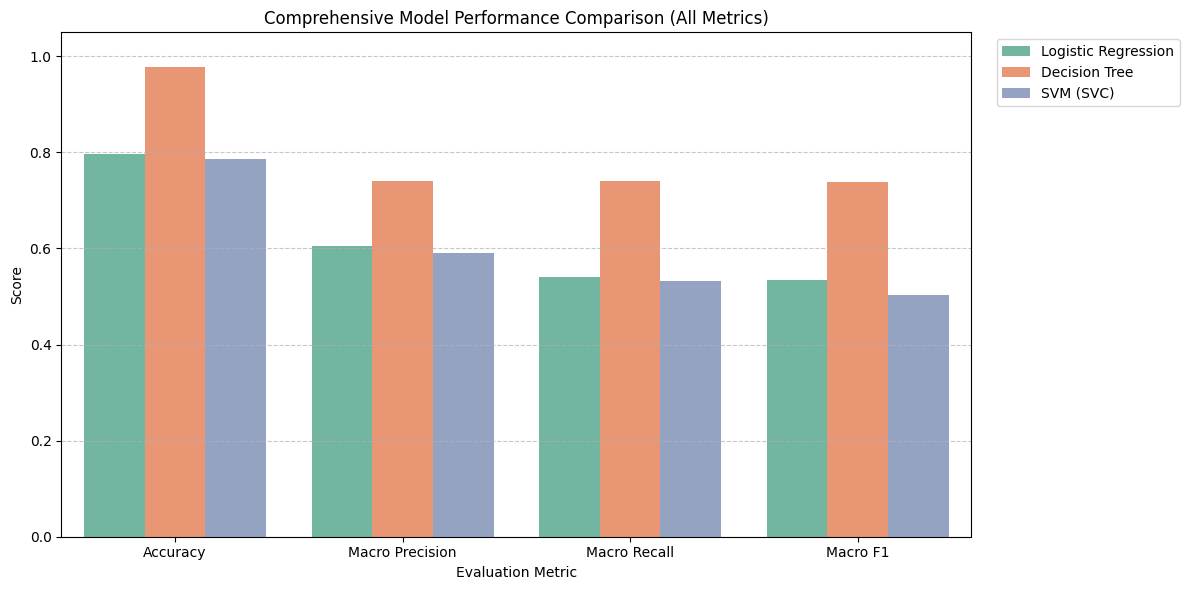

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Helper function to extract macro averages from our predictions
def get_metrics(y_true, preds):
    acc = accuracy_score(y_true, preds)
    # macro avg treats all attack classes equally (crucial for rare attacks)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, preds, average='macro', zero_division=0)
    return [acc, prec, rec, f1]

# Collect metrics for all three models
lr_metrics = get_metrics(y_test, lr_preds)
dt_metrics = get_metrics(y_test, dt_preds)
svc_metrics = get_metrics(y_test, svc_preds)

# Create a comprehensive comparison DataFrame
metrics_data = {
    "Model": ["Logistic Regression", "Logistic Regression", "Logistic Regression", "Logistic Regression",
              "Decision Tree", "Decision Tree", "Decision Tree", "Decision Tree",
              "SVM (SVC)", "SVM (SVC)", "SVM (SVC)", "SVM (SVC)"],
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"] * 3,
    "Score": lr_metrics + dt_metrics + svc_metrics
}

df_metrics = pd.DataFrame(metrics_data)

# Plot grouped bar chart
plt.figure(figsize=(12, 6))
sns.barplot(x="Metric", y="Score", hue="Model", data=df_metrics, palette="Set2")
plt.title("Comprehensive Model Performance Comparison (All Metrics)")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ***Hyperparameter tuning three parts:***

1.  max_depth: Caps tree growth to prevent overfitting.
2.  min_samples_split: Requires a minimum sample count to split nodes, blocking hyper-specific branches.
3. class_weight='balanced': Penalizes mistakes on rare minority attacks to ensure they aren't ignored.






In [17]:
'''from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

# Fully optimized Decision Tree with all tuning guardrails
dt_final_optimized = DecisionTreeClassifier(
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=1,      # Ensures leaf nodes have at least 2 samples
    class_weight='balanced', # Penalizes mistakes on rare attack classes
    random_state=42
)

dt_final_optimized.fit(X_train, y_train)
final_preds = dt_final_optimized.predict(X_test)

print("--- Fully Optimized Decision Tree Report ---")
print(f"Accuracy: {accuracy_score(y_test, final_preds):.4f}")
print(classification_report(y_test, final_preds, zero_division=0))'''

'from sklearn.tree import DecisionTreeClassifier\nfrom sklearn.metrics import classification_report, accuracy_score\n\n# Fully optimized Decision Tree with all tuning guardrails\ndt_final_optimized = DecisionTreeClassifier(\n    max_depth=30,\n    min_samples_split=5,\n    min_samples_leaf=1,      # Ensures leaf nodes have at least 2 samples\n    class_weight=\'balanced\', # Penalizes mistakes on rare attack classes\n    random_state=42\n)\n\ndt_final_optimized.fit(X_train, y_train)\nfinal_preds = dt_final_optimized.predict(X_test)\n\nprint("--- Fully Optimized Decision Tree Report ---")\nprint(f"Accuracy: {accuracy_score(y_test, final_preds):.4f}")\nprint(classification_report(y_test, final_preds, zero_division=0))'

In [18]:
'''# --- Quick Small-Scale Test in Colab ---
# Take the first 5 rows of your test data
sample_data = X_test[:5]
sample_actuals = y_test[:5]

# Predict using your fully optimized model
sample_preds = dt_final_optimized.predict(sample_data)

print("Predictions on 5 test samples:")
for actual, pred in zip(sample_actuals, sample_preds):
    print(f"Actual: {actual} | Predicted: {pred}")'''

'# --- Quick Small-Scale Test in Colab ---\n# Take the first 5 rows of your test data\nsample_data = X_test[:5]\nsample_actuals = y_test[:5]\n\n# Predict using your fully optimized model\nsample_preds = dt_final_optimized.predict(sample_data)\n\nprint("Predictions on 5 test samples:")\nfor actual, pred in zip(sample_actuals, sample_preds):\n    print(f"Actual: {actual} | Predicted: {pred}")'

In [19]:
# --- 2. Save with Joblib ---
import joblib

joblib.dump(dt_final_optimized, '/content/drive/MyDrive/ML projects/iot_intrusion.pkl')
print("\nModel successfully saved to Google Drive!")


Model successfully saved to Google Drive!


In [20]:
import joblib

joblib.dump(scaler, '/content/drive/MyDrive/ML projects/scaler.pkl')
print("Scaler saved successfully!")

Scaler saved successfully!
